# Load and Read Dataset

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"

warnings.filterwarnings("ignore")
warnings.simplefilter("ignore")

_original_warn = warnings.warn

def suppress_all_warnings(message, *args, **kwargs):
    return None

warnings.warn = suppress_all_warnings

print("Warning messages are disabled for this notebook.")

Warning messages are disabled for this notebook.


In [2]:
import pandas as pd

# Load feature names
features = pd.read_csv(
    "features.txt",
    sep=r"\s+",
    header=None,
    names=["index", "feature"]
)

# Load activity labels
activity_labels = pd.read_csv(
    "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity"]
)

# Load training data
X_train = pd.read_csv(
    "train/X_train.txt",
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    "train/y_train.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id"]
)

# Load testing data
X_test = pd.read_csv(
    "test/X_test.txt",
    sep=r"\s+",
    header=None
)

y_test = pd.read_csv(
    "test/y_test.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id"]
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

print("\nNumber of features:", len(features))
print("Number of activities:", len(activity_labels))

X_train shape: (7352, 561)
y_train shape: (7352, 1)
X_test shape : (2947, 561)
y_test shape : (2947, 1)

Number of features: 561
Number of activities: 6


# Analysis features and Activities

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

X_opt, X_val, y_opt, y_val = train_test_split(
    X_train,
    y_train["activity_id"],
    test_size=0.20,
    random_state=42,
    stratify=y_train["activity_id"]
)

print("Optimization training samples:", X_opt.shape[0])
print("Validation samples:", X_val.shape[0])
print("Number of features:", X_opt.shape[1])

Optimization training samples: 5881
Validation samples: 1471
Number of features: 561


# Algorithms

## GA

In [4]:
import numpy as np
import pandas as pd
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


total_features = X_opt.shape[1]
lambda_penalty = 0.01


def evaluate_solution(solution, max_features):
    selected_features = np.where(solution == 1)[0]
    number_selected = len(selected_features)

    if number_selected == 0:
        return float("inf"), 0, 0, 0

    if number_selected > max_features:
        return float("inf"), number_selected, 0, 0

    X_opt_selected = X_opt.iloc[:, selected_features]
    X_val_selected = X_val.iloc[:, selected_features]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_opt_selected, y_opt)

    predictions = model.predict(X_val_selected)

    accuracy = accuracy_score(y_val, predictions)
    f1 = f1_score(y_val, predictions, average="macro")

    error = 1 - accuracy
    feature_ratio = number_selected / total_features

    fitness = error + lambda_penalty * feature_ratio

    return fitness, number_selected, accuracy, f1


def create_individual(max_features):
    solution = np.zeros(total_features, dtype=int)

    number_selected = np.random.randint(
        1,
        max_features + 1
    )

    selected_indices = np.random.choice(
        total_features,
        size=number_selected,
        replace=False
    )

    solution[selected_indices] = 1

    return solution


def create_population(population_size, max_features):
    population = []

    for _ in range(population_size):
        population.append(
            create_individual(max_features)
        )

    return np.array(population)


def evaluate_population(population, max_features):
    fitness_values = []
    feature_counts = []
    accuracies = []
    f1_scores = []

    for solution in population:
        fitness, feature_count, accuracy, f1 = evaluate_solution(
            solution,
            max_features
        )

        fitness_values.append(fitness)
        feature_counts.append(feature_count)
        accuracies.append(accuracy)
        f1_scores.append(f1)

    return (
        np.array(fitness_values),
        np.array(feature_counts),
        np.array(accuracies),
        np.array(f1_scores)
    )


def tournament_selection(
    population,
    fitness_values,
    tournament_size=3
):
    selected_indices = []

    population_size = len(population)

    for _ in range(population_size):
        candidates = np.random.choice(
            population_size,
            size=tournament_size,
            replace=False
        )

        winner = candidates[
            np.argmin(fitness_values[candidates])
        ]

        selected_indices.append(winner)

    return population[selected_indices].copy()


def crossover(
    parent1,
    parent2,
    crossover_rate=0.8
):
    child1 = parent1.copy()
    child2 = parent2.copy()

    if np.random.rand() < crossover_rate:
        point = np.random.randint(
            1,
            total_features - 1
        )

        child1[:point] = parent1[:point]
        child1[point:] = parent2[point:]

        child2[:point] = parent2[:point]
        child2[point:] = parent1[point:]

    return child1, child2


def repair_solution(solution, max_features):
    selected_indices = np.where(solution == 1)[0]

    if len(selected_indices) > max_features:
        remove_count = len(selected_indices) - max_features

        remove_indices = np.random.choice(
            selected_indices,
            size=remove_count,
            replace=False
        )

        solution[remove_indices] = 0

    if solution.sum() == 0:
        random_index = np.random.randint(total_features)
        solution[random_index] = 1

    return solution


def mutate(
    solution,
    mutation_rate=0.01
):
    mutation_mask = (
        np.random.rand(total_features) < mutation_rate
    )

    solution[mutation_mask] = (
        1 - solution[mutation_mask]
    )

    return solution


def run_genetic_algorithm(
    problem_name,
    max_features,
    population_size=20,
    generations=20,
    crossover_rate=0.8,
    mutation_rate=0.01,
    tournament_size=3,
    elitism=1,
    random_seed=42
):
    np.random.seed(random_seed)

    start_time = time.time()

    population = create_population(
        population_size,
        max_features
    )

    best_solution = None
    best_fitness = float("inf")
    best_accuracy = 0.0
    best_f1 = 0.0
    best_feature_count = 0

    convergence_history = []

    for generation in range(generations):

        fitness_values, feature_counts, accuracies, f1_scores = (
            evaluate_population(
                population,
                max_features
            )
        )

        generation_best_index = np.argmin(
            fitness_values
        )

        generation_best_fitness = (
            fitness_values[generation_best_index]
        )

        if generation_best_fitness < best_fitness:

            best_fitness = generation_best_fitness

            best_solution = (
                population[generation_best_index].copy()
            )

            best_accuracy = (
                accuracies[generation_best_index]
            )

            best_f1 = (
                f1_scores[generation_best_index]
            )

            best_feature_count = (
                feature_counts[generation_best_index]
            )

        convergence_history.append({
            "Generation": generation + 1,
            "Best Fitness": best_fitness,
            "Best Accuracy": best_accuracy,
            "Best Macro-F1": best_f1,
            "Selected Features": best_feature_count
        })

        print(
            f"Generation {generation + 1}/{generations} | "
            f"Fitness: {best_fitness:.6f} | "
            f"Features: {best_feature_count} | "
            f"Accuracy: {best_accuracy:.4f}"
        )

        selected_population = tournament_selection(
            population,
            fitness_values,
            tournament_size
        )

        new_population = []

        elite_indices = np.argsort(
            fitness_values
        )[:elitism]

        for index in elite_indices:
            new_population.append(
                population[index].copy()
            )

        while len(new_population) < population_size:

            parent_indices = np.random.choice(
                len(selected_population),
                size=2,
                replace=False
            )

            parent1 = selected_population[
                parent_indices[0]
            ]

            parent2 = selected_population[
                parent_indices[1]
            ]

            child1, child2 = crossover(
                parent1,
                parent2,
                crossover_rate
            )

            child1 = mutate(
                child1,
                mutation_rate
            )

            child2 = mutate(
                child2,
                mutation_rate
            )

            child1 = repair_solution(
                child1,
                max_features
            )

            child2 = repair_solution(
                child2,
                max_features
            )

            new_population.append(child1)

            if len(new_population) < population_size:
                new_population.append(child2)

        population = np.array(new_population)

    runtime = time.time() - start_time

    result = {
        "Algorithm": "GA",
        "Problem Size": problem_name,
        "Max Features": max_features,
        "Best Fitness": best_fitness,
        "Selected Features": best_feature_count,
        "Validation Accuracy": best_accuracy,
        "Validation Macro-F1": best_f1,
        "Runtime (seconds)": runtime,
        "Best Solution": best_solution,
        "Convergence": pd.DataFrame(
            convergence_history
        )
    }

    return result

# PSO

In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


total_features = X_opt.shape[1]
lambda_penalty = 0.01


def evaluate_pso_solution(solution, max_features):
    selected_features = np.where(solution == 1)[0]
    number_selected = len(selected_features)

    if number_selected == 0:
        return float("inf"), 0, 0, 0

    if number_selected > max_features:
        return float("inf"), number_selected, 0, 0

    X_opt_selected = X_opt.iloc[:, selected_features]
    X_val_selected = X_val.iloc[:, selected_features]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_opt_selected, y_opt)

    predictions = model.predict(X_val_selected)

    accuracy = accuracy_score(y_val, predictions)
    f1 = f1_score(y_val, predictions, average="macro")

    error = 1 - accuracy
    feature_ratio = number_selected / total_features

    fitness = error + lambda_penalty * feature_ratio

    return fitness, number_selected, accuracy, f1


def create_pso_particle(max_features):
    position = np.zeros(total_features, dtype=int)

    number_selected = np.random.randint(
        1,
        max_features + 1
    )

    selected_indices = np.random.choice(
        total_features,
        size=number_selected,
        replace=False
    )

    position[selected_indices] = 1

    velocity = np.random.uniform(
        -1,
        1,
        total_features
    )

    return position, velocity


def repair_pso_position(position, max_features):
    selected_indices = np.where(position == 1)[0]

    if len(selected_indices) > max_features:
        remove_count = len(selected_indices) - max_features

        remove_indices = np.random.choice(
            selected_indices,
            size=remove_count,
            replace=False
        )

        position[remove_indices] = 0

    if position.sum() == 0:
        random_index = np.random.randint(total_features)
        position[random_index] = 1

    return position


def run_particle_swarm_optimization(
    problem_name,
    max_features,
    swarm_size=20,
    iterations=20,
    inertia=0.7,
    cognitive=1.5,
    social=1.5,
    random_seed=42
):
    np.random.seed(random_seed)

    start_time = time.time()

    positions = []
    velocities = []

    for _ in range(swarm_size):
        position, velocity = create_pso_particle(
            max_features
        )

        positions.append(position)
        velocities.append(velocity)

    positions = np.array(positions)
    velocities = np.array(velocities)

    personal_best_positions = positions.copy()

    personal_best_fitness = np.full(
        swarm_size,
        float("inf")
    )

    global_best_position = None
    global_best_fitness = float("inf")
    global_best_accuracy = 0
    global_best_f1 = 0
    global_best_feature_count = 0

    convergence_history = []

    for iteration in range(iterations):

        for i in range(swarm_size):

            fitness, feature_count, accuracy, f1 = (
                evaluate_pso_solution(
                    positions[i],
                    max_features
                )
            )

            if fitness < personal_best_fitness[i]:
                personal_best_fitness[i] = fitness
                personal_best_positions[i] = positions[i].copy()

            if fitness < global_best_fitness:
                global_best_fitness = fitness
                global_best_position = positions[i].copy()
                global_best_accuracy = accuracy
                global_best_f1 = f1
                global_best_feature_count = feature_count

        convergence_history.append({
            "Iteration": iteration + 1,
            "Best Fitness": global_best_fitness,
            "Best Accuracy": global_best_accuracy,
            "Best Macro-F1": global_best_f1,
            "Selected Features": global_best_feature_count
        })

        print(
            f"Iteration {iteration + 1}/{iterations} | "
            f"Fitness: {global_best_fitness:.6f} | "
            f"Features: {global_best_feature_count} | "
            f"Accuracy: {global_best_accuracy:.4f}"
        )

        for i in range(swarm_size):

            r1 = np.random.rand(total_features)
            r2 = np.random.rand(total_features)

            velocities[i] = (
                inertia * velocities[i]
                + cognitive * r1
                * (
                    personal_best_positions[i]
                    - positions[i]
                )
                + social * r2
                * (
                    global_best_position
                    - positions[i]
                )
            )

            sigmoid = 1 / (
                1 + np.exp(
                    -np.clip(
                        velocities[i],
                        -20,
                        20
                    )
                )
            )

            random_values = np.random.rand(
                total_features
            )

            positions[i] = (
                random_values < sigmoid
            ).astype(int)

            positions[i] = repair_pso_position(
                positions[i],
                max_features
            )

    runtime = time.time() - start_time

    return {
        "Algorithm": "PSO",
        "Problem Size": problem_name,
        "Max Features": max_features,
        "Best Fitness": global_best_fitness,
        "Selected Features": global_best_feature_count,
        "Validation Accuracy": global_best_accuracy,
        "Validation Macro-F1": global_best_f1,
        "Runtime (seconds)": runtime,
        "Best Solution": global_best_position,
        "Convergence": pd.DataFrame(convergence_history)
    }

# ACO

In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


total_features = X_opt.shape[1]
lambda_penalty = 0.01


def evaluate_aco_solution(solution, max_features):
    selected_features = np.where(solution == 1)[0]
    number_selected = len(selected_features)

    if number_selected == 0:
        return float("inf"), 0, 0, 0

    if number_selected > max_features:
        return float("inf"), number_selected, 0, 0

    X_opt_selected = X_opt.iloc[:, selected_features]
    X_val_selected = X_val.iloc[:, selected_features]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_opt_selected, y_opt)

    predictions = model.predict(X_val_selected)

    accuracy = accuracy_score(y_val, predictions)
    f1 = f1_score(y_val, predictions, average="macro")

    error = 1 - accuracy
    feature_ratio = number_selected / total_features

    fitness = error + lambda_penalty * feature_ratio

    return fitness, number_selected, accuracy, f1


def create_aco_solution(
    pheromone,
    max_features,
    alpha=1.0
):
    probabilities = (
        pheromone ** alpha
    )

    probabilities = probabilities / probabilities.sum()

    number_selected = np.random.randint(
        1,
        max_features + 1
    )

    selected_indices = np.random.choice(
        total_features,
        size=number_selected,
        replace=False,
        p=probabilities
    )

    solution = np.zeros(
        total_features,
        dtype=int
    )

    solution[selected_indices] = 1

    return solution


def repair_aco_solution(
    solution,
    max_features,
    pheromone
):
    selected_indices = np.where(solution == 1)[0]

    if len(selected_indices) > max_features:

        remove_count = (
            len(selected_indices) - max_features
        )

        remove_probabilities = (
            pheromone[selected_indices]
        )

        remove_probabilities = (
            remove_probabilities
            / remove_probabilities.sum()
        )

        remove_indices = np.random.choice(
            selected_indices,
            size=remove_count,
            replace=False,
            p=remove_probabilities
        )

        solution[remove_indices] = 0

    if solution.sum() == 0:
        solution[
            np.random.randint(total_features)
        ] = 1

    return solution


def run_ant_colony_optimization(
    problem_name,
    max_features,
    number_ants=20,
    iterations=20,
    evaporation_rate=0.5,
    pheromone_weight=1.0,
    pheromone_deposit=1.0,
    random_seed=42
):
    np.random.seed(random_seed)

    start_time = time.time()

    pheromone = np.ones(
        total_features
    )

    best_solution = None
    best_fitness = float("inf")
    best_accuracy = 0
    best_f1 = 0
    best_feature_count = 0

    convergence_history = []

    for iteration in range(iterations):

        ant_solutions = []
        ant_fitnesses = []
        ant_feature_counts = []
        ant_accuracies = []
        ant_f1_scores = []

        for ant in range(number_ants):

            solution = create_aco_solution(
                pheromone,
                max_features,
                alpha=pheromone_weight
            )

            solution = repair_aco_solution(
                solution,
                max_features,
                pheromone
            )

            fitness, feature_count, accuracy, f1 = (
                evaluate_aco_solution(
                    solution,
                    max_features
                )
            )

            ant_solutions.append(solution)
            ant_fitnesses.append(fitness)
            ant_feature_counts.append(feature_count)
            ant_accuracies.append(accuracy)
            ant_f1_scores.append(f1)

            if fitness < best_fitness:

                best_fitness = fitness
                best_solution = solution.copy()
                best_accuracy = accuracy
                best_f1 = f1
                best_feature_count = feature_count

        pheromone *= (
            1 - evaporation_rate
        )

        for ant in range(number_ants):

            solution = ant_solutions[ant]
            fitness = ant_fitnesses[ant]

            if np.isfinite(fitness):

                deposit = (
                    pheromone_deposit
                    / (fitness + 1e-10)
                )

                selected_indices = np.where(
                    solution == 1
                )[0]

                pheromone[selected_indices] += deposit

        convergence_history.append({
            "Iteration": iteration + 1,
            "Best Fitness": best_fitness,
            "Best Accuracy": best_accuracy,
            "Best Macro-F1": best_f1,
            "Selected Features": best_feature_count
        })

        print(
            f"Iteration {iteration + 1}/{iterations} | "
            f"Fitness: {best_fitness:.6f} | "
            f"Features: {best_feature_count} | "
            f"Accuracy: {best_accuracy:.4f}"
        )

    runtime = time.time() - start_time

    return {
        "Algorithm": "ACO",
        "Problem Size": problem_name,
        "Max Features": max_features,
        "Best Fitness": best_fitness,
        "Selected Features": best_feature_count,
        "Validation Accuracy": best_accuracy,
        "Validation Macro-F1": best_f1,
        "Runtime (seconds)": runtime,
        "Best Solution": best_solution,
        "Convergence": pd.DataFrame(
            convergence_history
        )
    }

In [7]:
import time
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score


def evaluate_final_solution(
    algorithm,
    problem_size,
    solution,
    n_estimators=100,
    random_state=42
):
    selected_features = np.where(solution == 1)[0]

    X_train_selected = X_train.iloc[:, selected_features]
    X_test_selected = X_test.iloc[:, selected_features]

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        random_state=random_state,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(
        X_train_selected,
        y_train["activity_id"]
    )

    training_time = time.time() - start_time

    start_time = time.time()

    predictions = model.predict(
        X_test_selected
    )

    prediction_time = time.time() - start_time

    accuracy = accuracy_score(
        y_test["activity_id"],
        predictions
    )

    macro_f1 = f1_score(
        y_test["activity_id"],
        predictions,
        average="macro"
    )

    feature_count = len(selected_features)

    feature_reduction = (
        (X_train.shape[1] - feature_count)
        / X_train.shape[1]
    ) * 100

    return {
        "Algorithm": algorithm,
        "Problem Size": problem_size,
        "Selected Features": feature_count,
        "Feature Reduction (%)": feature_reduction,
        "Test Accuracy": accuracy,
        "Test Macro-F1": macro_f1,
        "Training Time (seconds)": training_time,
        "Prediction Time (seconds)": prediction_time
    }

# Stability

In [8]:
import inspect

print("GA:")
print(inspect.signature(run_genetic_algorithm))

print("\nPSO:")
print(inspect.signature(run_particle_swarm_optimization))

print("\nACO:")
print(inspect.signature(run_ant_colony_optimization))

GA:
(problem_name, max_features, population_size=20, generations=20, crossover_rate=0.8, mutation_rate=0.01, tournament_size=3, elitism=1, random_seed=42)

PSO:
(problem_name, max_features, swarm_size=20, iterations=20, inertia=0.7, cognitive=1.5, social=1.5, random_seed=42)

ACO:
(problem_name, max_features, number_ants=20, iterations=20, evaporation_rate=0.5, pheromone_weight=1.0, pheromone_deposit=1.0, random_seed=42)


In [9]:
import inspect

print("GA return structure:")
print(inspect.getsource(run_genetic_algorithm)[-2000:])

print("\nPSO return structure:")
print(inspect.getsource(run_particle_swarm_optimization)[-2000:])

print("\nACO return structure:")
print(inspect.getsource(run_ant_colony_optimization)[-2000:])

GA return structure:
 = tournament_selection(
            population,
            fitness_values,
            tournament_size
        )

        new_population = []

        elite_indices = np.argsort(
            fitness_values
        )[:elitism]

        for index in elite_indices:
            new_population.append(
                population[index].copy()
            )

        while len(new_population) < population_size:

            parent_indices = np.random.choice(
                len(selected_population),
                size=2,
                replace=False
            )

            parent1 = selected_population[
                parent_indices[0]
            ]

            parent2 = selected_population[
                parent_indices[1]
            ]

            child1, child2 = crossover(
                parent1,
                parent2,
                crossover_rate
            )

            child1 = mutate(
                child1,
                mutation_rate
        

In [10]:
import time
import pandas as pd
import warnings
import time
import pandas as pd
import warnings
import os

warnings.filterwarnings("ignore")
warnings.simplefilter("ignore")

os.environ["PYTHONWARNINGS"] = "ignore"

warnings.filterwarnings(
    "ignore",
    message=".*sklearn.utils.parallel.delayed.*",
    category=UserWarning
)

seeds = [42, 43, 44]

problem_sizes = {
    "Small": 100,
    "Medium": 300,
    "Large": 561
}


stability_results = []

for seed in seeds:

    print("\n" + "=" * 70)
    print(f"RUNNING SEED: {seed}")
    print("=" * 70)

    for problem_name, max_features in problem_sizes.items():

        print("\n" + "-" * 70)
        print(f"Problem Size: {problem_name} | Max Features: {max_features}")
        print("-" * 70)

        print("\nGA")
        ga_result = run_genetic_algorithm(
            problem_name=problem_name,
            max_features=max_features,
            population_size=20,
            generations=20,
            crossover_rate=0.8,
            mutation_rate=0.01,
            tournament_size=3,
            elitism=1,
            random_seed=seed
        )

        stability_results.append({
            "Seed": seed,
            "Algorithm": "GA",
            "Problem Size": problem_name,
            "Max Features": max_features,
            "Best Fitness": ga_result["Best Fitness"],
            "Selected Features": ga_result["Selected Features"],
            "Validation Accuracy": ga_result["Validation Accuracy"],
            "Validation Macro-F1": ga_result["Validation Macro-F1"],
            "Runtime (seconds)": ga_result["Runtime (seconds)"]
        })

        print("\nPSO")
        pso_result = run_particle_swarm_optimization(
            problem_name=problem_name,
            max_features=max_features,
            swarm_size=20,
            iterations=20,
            inertia=0.7,
            cognitive=1.5,
            social=1.5,
            random_seed=seed
        )

        stability_results.append({
            "Seed": seed,
            "Algorithm": "PSO",
            "Problem Size": problem_name,
            "Max Features": max_features,
            "Best Fitness": pso_result["Best Fitness"],
            "Selected Features": pso_result["Selected Features"],
            "Validation Accuracy": pso_result["Validation Accuracy"],
            "Validation Macro-F1": pso_result["Validation Macro-F1"],
            "Runtime (seconds)": pso_result["Runtime (seconds)"]
        })

        print("\nACO")
        aco_result = run_ant_colony_optimization(
            problem_name=problem_name,
            max_features=max_features,
            number_ants=20,
            iterations=20,
            evaporation_rate=0.5,
            pheromone_weight=1.0,
            pheromone_deposit=1.0,
            random_seed=seed
        )

        stability_results.append({
            "Seed": seed,
            "Algorithm": "ACO",
            "Problem Size": problem_name,
            "Max Features": max_features,
            "Best Fitness": aco_result["Best Fitness"],
            "Selected Features": aco_result["Selected Features"],
            "Validation Accuracy": aco_result["Validation Accuracy"],
            "Validation Macro-F1": aco_result["Validation Macro-F1"],
            "Runtime (seconds)": aco_result["Runtime (seconds)"]
        })

stability_df = pd.DataFrame(stability_results)

print("\nStability experiments completed.")
print("Number of experiments:", len(stability_df))

display(stability_df)


RUNNING SEED: 42

----------------------------------------------------------------------
Problem Size: Small | Max Features: 100
----------------------------------------------------------------------

GA
Generation 1/20 | Fitness: 0.025415 | Features: 91 | Accuracy: 0.9762
Generation 2/20 | Fitness: 0.021892 | Features: 84 | Accuracy: 0.9796
Generation 3/20 | Fitness: 0.019386 | Features: 96 | Accuracy: 0.9823
Generation 4/20 | Fitness: 0.019386 | Features: 96 | Accuracy: 0.9823
Generation 5/20 | Fitness: 0.018778 | Features: 100 | Accuracy: 0.9830
Generation 6/20 | Fitness: 0.018778 | Features: 100 | Accuracy: 0.9830
Generation 7/20 | Fitness: 0.016738 | Features: 100 | Accuracy: 0.9850
Generation 8/20 | Fitness: 0.016023 | Features: 98 | Accuracy: 0.9857
Generation 9/20 | Fitness: 0.016023 | Features: 98 | Accuracy: 0.9857
Generation 10/20 | Fitness: 0.015379 | Features: 100 | Accuracy: 0.9864
Generation 11/20 | Fitness: 0.015379 | Features: 100 | Accuracy: 0.9864
Generation 12/20 |

,Seed,Algorithm,Problem Size,Max Features,Best Fitness,Selected Features,Validation Accuracy,Validation Macro-F1,Runtime (seconds)
0,42,GA,Small,100,0.014699,100,0.987084,0.987337,1297.054397
1,42,PSO,Small,100,0.015379,100,0.986404,0.986762,1381.928849
2,42,ACO,Small,100,0.017813,84,0.983685,0.983672,989.992857
3,42,GA,Medium,300,0.014857,147,0.987763,0.987894,1571.931177
4,42,PSO,Medium,300,0.018409,270,0.986404,0.986709,6370.152082
5,42,ACO,Medium,300,0.017184,125,0.985044,0.985431,1193.387255
6,42,GA,Large,561,0.015730,196,0.987763,0.988248,1513.783088
7,42,PSO,Large,561,0.018498,275,0.986404,0.986501,1729.907009
8,42,ACO,Large,561,0.018989,150,0.983685,0.983886,1600.832824
9,43,GA,Small,100,0.016059,100,0.985724,0.985977,1018.166516


In [12]:
stability_summary = (
    stability_df
    .groupby(["Algorithm", "Problem Size"])
    .agg(
        Mean_Fitness=("Best Fitness", "mean"),
        Std_Fitness=("Best Fitness", "std"),
        Mean_Accuracy=("Validation Accuracy", "mean"),
        Std_Accuracy=("Validation Accuracy", "std"),
        Mean_Macro_F1=("Validation Macro-F1", "mean"),
        Std_Macro_F1=("Validation Macro-F1", "std"),
        Mean_Selected_Features=("Selected Features", "mean"),
        Std_Selected_Features=("Selected Features", "std"),
        Mean_Runtime=("Runtime (seconds)", "mean"),
        Std_Runtime=("Runtime (seconds)", "std")
    )
    .reset_index()
)

display(stability_summary)

,Algorithm,Problem Size,Mean_Fitness,Std_Fitness,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1,Std_Macro_F1,Mean_Selected_Features,Std_Selected_Features,Mean_Runtime,Std_Runtime
0,ACO,Large,0.019246,0.000490,0.983231,0.000392,0.983204,0.000691,139.000000,26.286879,1675.596679,84.466299
1,ACO,Medium,0.017388,0.000721,0.984364,0.001177,0.984560,0.001526,98.333333,29.280255,1294.211991,164.268062
2,ACO,Small,0.017115,0.000606,0.984364,0.000680,0.984642,0.001042,83.000000,16.522712,984.281508,15.680998
3,GA,Large,0.016361,0.001266,0.987537,0.000392,0.987952,0.000555,218.666667,49.095146,12467.359869,19109.779715
4,GA,Medium,0.015810,0.001572,0.987084,0.000680,0.987348,0.000649,162.333333,57.552874,1640.624377,187.515843
5,GA,Small,0.015146,0.000790,0.986630,0.000785,0.986823,0.000738,99.666667,0.577350,1208.167705,164.659402
6,PSO,Large,0.018279,0.000206,0.986177,0.000392,0.986526,0.000459,250.000000,26.057628,1729.487228,27.144648
7,PSO,Medium,0.018361,0.000237,0.986630,0.000392,0.986956,0.000345,280.000000,10.535654,4726.444270,2368.445074
8,PSO,Small,0.015379,0.000680,0.986404,0.000680,0.986847,0.000568,100.000000,0.000000,1314.130067,130.052562


In [13]:
stability_formatted = stability_summary.copy()

stability_formatted["Accuracy Mean ± Std (%)"] = (
    stability_formatted["Mean_Accuracy"] * 100
).round(2).astype(str) + " ± " + (
    stability_formatted["Std_Accuracy"] * 100
).round(2).astype(str)

stability_formatted["Macro-F1 Mean ± Std (%)"] = (
    stability_formatted["Mean_Macro_F1"] * 100
).round(2).astype(str) + " ± " + (
    stability_formatted["Std_Macro_F1"] * 100
).round(2).astype(str)

stability_formatted["Fitness Mean ± Std"] = (
    stability_formatted["Mean_Fitness"].round(5).astype(str) + " ± " +
    stability_formatted["Std_Fitness"].round(5).astype(str)
)

stability_formatted["Features Mean ± Std"] = (
    stability_formatted["Mean_Selected_Features"].round(2).astype(str) + " ± " +
    stability_formatted["Std_Selected_Features"].round(2).astype(str)
)

stability_formatted["Runtime Mean ± Std (s)"] = (
    stability_formatted["Mean_Runtime"].round(2).astype(str) + " ± " +
    stability_formatted["Std_Runtime"].round(2).astype(str)
)

stability_formatted = stability_formatted[
    [
        "Algorithm",
        "Problem Size",
        "Accuracy Mean ± Std (%)",
        "Macro-F1 Mean ± Std (%)",
        "Fitness Mean ± Std",
        "Features Mean ± Std",
        "Runtime Mean ± Std (s)"
    ]
]

display(stability_formatted)

,Algorithm,Problem Size,Accuracy Mean ± Std (%),Macro-F1 Mean ± Std (%),Fitness Mean ± Std,Features Mean ± Std,Runtime Mean ± Std (s)
0,ACO,Large,98.32 ± 0.04,98.32 ± 0.07,0.01925 ± 0.00049,139.0 ± 26.29,1675.6 ± 84.47
1,ACO,Medium,98.44 ± 0.12,98.46 ± 0.15,0.01739 ± 0.00072,98.33 ± 29.28,1294.21 ± 164.27
2,ACO,Small,98.44 ± 0.07,98.46 ± 0.1,0.01712 ± 0.00061,83.0 ± 16.52,984.28 ± 15.68
3,GA,Large,98.75 ± 0.04,98.8 ± 0.06,0.01636 ± 0.00127,218.67 ± 49.1,12467.36 ± 19109.78
4,GA,Medium,98.71 ± 0.07,98.73 ± 0.06,0.01581 ± 0.00157,162.33 ± 57.55,1640.62 ± 187.52
5,GA,Small,98.66 ± 0.08,98.68 ± 0.07,0.01515 ± 0.00079,99.67 ± 0.58,1208.17 ± 164.66
6,PSO,Large,98.62 ± 0.04,98.65 ± 0.05,0.01828 ± 0.00021,250.0 ± 26.06,1729.49 ± 27.14
7,PSO,Medium,98.66 ± 0.04,98.7 ± 0.03,0.01836 ± 0.00024,280.0 ± 10.54,4726.44 ± 2368.45
8,PSO,Small,98.64 ± 0.07,98.68 ± 0.06,0.01538 ± 0.00068,100.0 ± 0.0,1314.13 ± 130.05


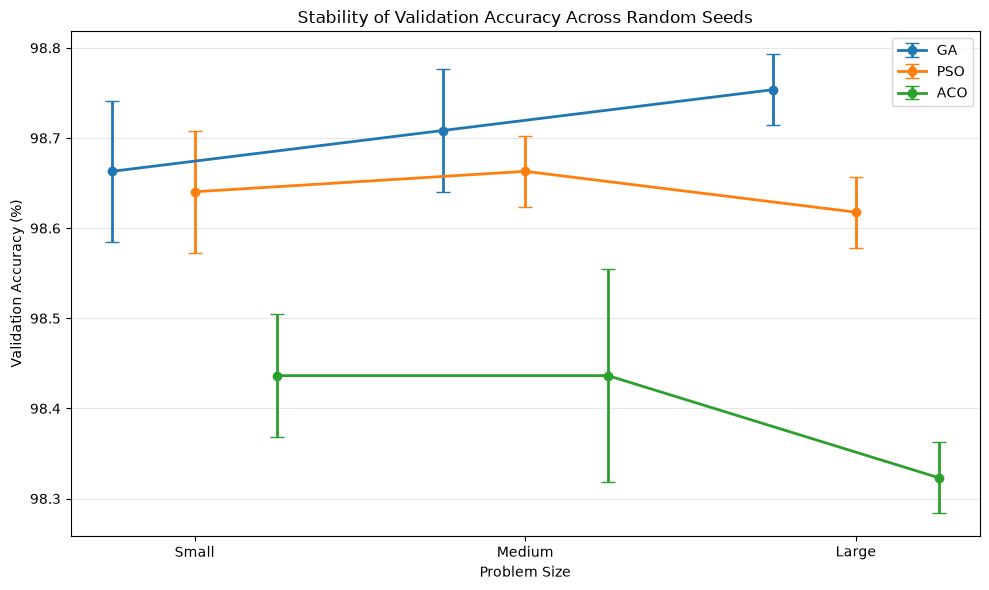

In [14]:
import matplotlib.pyplot as plt
import numpy as np

algorithms = ["GA", "PSO", "ACO"]
problem_sizes_order = ["Small", "Medium", "Large"]

x = np.arange(len(problem_sizes_order))
width = 0.25

plt.figure(figsize=(10, 6))

for i, algorithm in enumerate(algorithms):
    data = stability_summary[
        stability_summary["Algorithm"] == algorithm
    ].set_index("Problem Size").loc[problem_sizes_order]

    plt.errorbar(
        x + (i - 1) * width,
        data["Mean_Accuracy"] * 100,
        yerr=data["Std_Accuracy"] * 100,
        marker="o",
        capsize=5,
        linewidth=2,
        label=algorithm
    )

plt.xticks(x, problem_sizes_order)
plt.xlabel("Problem Size")
plt.ylabel("Validation Accuracy (%)")
plt.title("Stability of Validation Accuracy Across Random Seeds")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

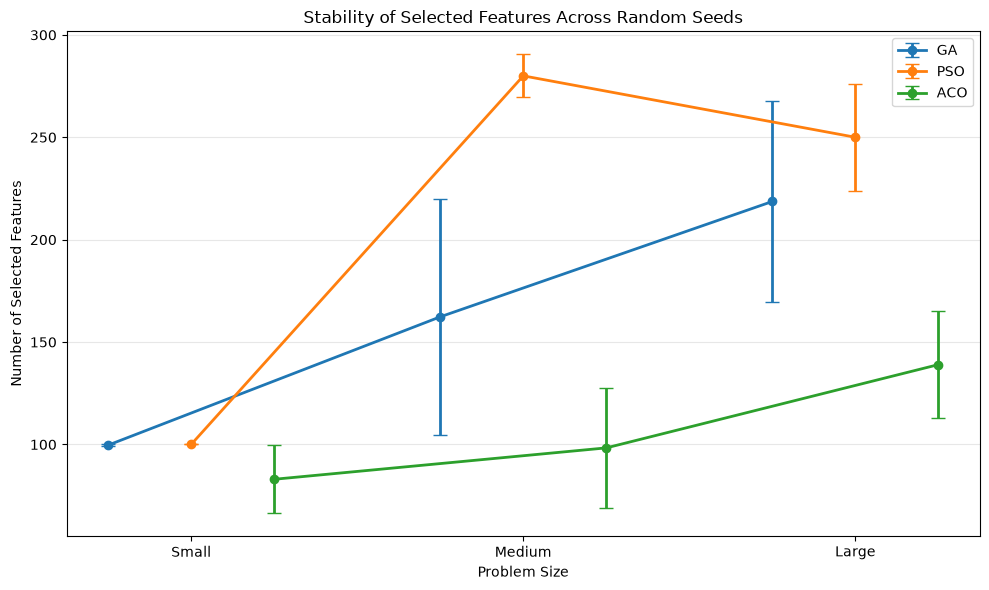

In [15]:
import matplotlib.pyplot as plt
import numpy as np

algorithms = ["GA", "PSO", "ACO"]
problem_sizes_order = ["Small", "Medium", "Large"]

x = np.arange(len(problem_sizes_order))
width = 0.25

plt.figure(figsize=(10, 6))

for i, algorithm in enumerate(algorithms):
    data = stability_summary[
        stability_summary["Algorithm"] == algorithm
    ].set_index("Problem Size").loc[problem_sizes_order]

    plt.errorbar(
        x + (i - 1) * width,
        data["Mean_Selected_Features"],
        yerr=data["Std_Selected_Features"],
        marker="o",
        capsize=5,
        linewidth=2,
        label=algorithm
    )

plt.xticks(x, problem_sizes_order)
plt.xlabel("Problem Size")
plt.ylabel("Number of Selected Features")
plt.title("Stability of Selected Features Across Random Seeds")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
stability_analysis = stability_summary.copy()

stability_analysis["Accuracy (%)"] = (
    stability_analysis["Mean_Accuracy"] * 100
).round(2)

stability_analysis["Accuracy Std (%)"] = (
    stability_analysis["Std_Accuracy"] * 100
).round(2)

stability_analysis["Macro-F1 (%)"] = (
    stability_analysis["Mean_Macro_F1"] * 100
).round(2)

stability_analysis["Macro-F1 Std (%)"] = (
    stability_analysis["Std_Macro_F1"] * 100
).round(2)

stability_analysis["Fitness"] = (
    stability_analysis["Mean_Fitness"]
).round(5)

stability_analysis["Fitness Std"] = (
    stability_analysis["Std_Fitness"]
).round(5)

stability_analysis["Selected Features"] = (
    stability_analysis["Mean_Selected_Features"]
).round(2)

stability_analysis["Features Std"] = (
    stability_analysis["Std_Selected_Features"]
).round(2)

stability_analysis = stability_analysis[
    [
        "Algorithm",
        "Problem Size",
        "Accuracy (%)",
        "Accuracy Std (%)",
        "Macro-F1 (%)",
        "Macro-F1 Std (%)",
        "Fitness",
        "Fitness Std",
        "Selected Features",
        "Features Std"
    ]
]

display(stability_analysis)

,Algorithm,Problem Size,Accuracy (%),Accuracy Std (%),Macro-F1 (%),Macro-F1 Std (%),Fitness,Fitness Std,Selected Features,Features Std
0,ACO,Large,98.32,0.04,98.32,0.07,0.01925,0.00049,139.00,26.29
1,ACO,Medium,98.44,0.12,98.46,0.15,0.01739,0.00072,98.33,29.28
2,ACO,Small,98.44,0.07,98.46,0.10,0.01712,0.00061,83.00,16.52
3,GA,Large,98.75,0.04,98.80,0.06,0.01636,0.00127,218.67,49.10
4,GA,Medium,98.71,0.07,98.73,0.06,0.01581,0.00157,162.33,57.55
5,GA,Small,98.66,0.08,98.68,0.07,0.01515,0.00079,99.67,0.58
6,PSO,Large,98.62,0.04,98.65,0.05,0.01828,0.00021,250.00,26.06
7,PSO,Medium,98.66,0.04,98.70,0.03,0.01836,0.00024,280.00,10.54
8,PSO,Small,98.64,0.07,98.68,0.06,0.01538,0.00068,100.00,0.00


In [17]:
stability_range = (
    stability_df
    .groupby(["Algorithm", "Problem Size"])
    .agg(
        Accuracy_Min=("Validation Accuracy", "min"),
        Accuracy_Max=("Validation Accuracy", "max"),
        Macro_F1_Min=("Validation Macro-F1", "min"),
        Macro_F1_Max=("Validation Macro-F1", "max"),
        Features_Min=("Selected Features", "min"),
        Features_Max=("Selected Features", "max"),
        Fitness_Min=("Best Fitness", "min"),
        Fitness_Max=("Best Fitness", "max")
    )
    .reset_index()
)

stability_range["Accuracy Range (%)"] = (
    (stability_range["Accuracy_Max"] - stability_range["Accuracy_Min"]) * 100
).round(3)

stability_range["Macro-F1 Range (%)"] = (
    (stability_range["Macro_F1_Max"] - stability_range["Macro_F1_Min"]) * 100
).round(3)

stability_range["Features Range"] = (
    stability_range["Features_Max"] - stability_range["Features_Min"]
)

stability_range["Fitness Range"] = (
    stability_range["Fitness_Max"] - stability_range["Fitness_Min"]
).round(5)

stability_range = stability_range[
    [
        "Algorithm",
        "Problem Size",
        "Accuracy Range (%)",
        "Macro-F1 Range (%)",
        "Features Range",
        "Fitness Range"
    ]
]

display(stability_range)

,Algorithm,Problem Size,Accuracy Range (%),Macro-F1 Range (%),Features Range,Fitness Range
0,ACO,Large,0.068,0.138,49,0.00087
1,ACO,Medium,0.204,0.265,58,0.00140
2,ACO,Small,0.136,0.207,33,0.00109
3,GA,Large,0.068,0.098,90,0.00228
4,GA,Medium,0.136,0.126,112,0.00277
5,GA,Small,0.136,0.136,1,0.00138
6,PSO,Large,0.068,0.092,52,0.00041
7,PSO,Medium,0.068,0.064,21,0.00047
8,PSO,Small,0.136,0.113,0,0.00136


In [18]:
final_comparison = pd.DataFrame({
    "Algorithm": [
        "Random Forest Baseline",
        "GA",
        "GA",
        "GA",
        "PSO",
        "PSO",
        "PSO",
        "ACO",
        "ACO",
        "ACO"
    ],
    "Problem Size": [
        "All Features",
        "Small",
        "Medium",
        "Large",
        "Small",
        "Medium",
        "Large",
        "Small",
        "Medium",
        "Large"
    ],
    "Selected Features": [
        561, 100, 147, 196, 100, 270, 275, 84, 125, 150
    ],
    "Feature Reduction (%)": [
        0.00, 82.17, 73.80, 65.06, 82.17, 51.87, 50.98, 85.03, 77.72, 73.26
    ],
    "Test Accuracy (%)": [
        92.57, 90.80, 93.18, 92.84, 91.82, 92.03, 93.65, 87.00, 91.96, 92.53
    ],
    "Test Macro-F1 (%)": [
        92.41, 90.47, 92.87, 92.55, 91.52, 91.81, 93.38, 86.87, 91.61, 92.34
    ],
    "Training Time (seconds)": [
        4.33, 1.81, 2.48, 2.94, 1.80, 3.02, 3.18, 1.68, 2.13, 2.43
    ],
    "Prediction Time (seconds)": [
        0.12, 0.10, 0.13, 0.12, 0.09, 0.10, 0.10, 0.11, 0.07, 0.10
    ]
})

display(final_comparison)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy (%),Test Macro-F1 (%),Training Time (seconds),Prediction Time (seconds)
0,Random Forest Baseline,All Features,561,0.00,92.57,92.41,4.33,0.12
1,GA,Small,100,82.17,90.80,90.47,1.81,0.10
2,GA,Medium,147,73.80,93.18,92.87,2.48,0.13
3,GA,Large,196,65.06,92.84,92.55,2.94,0.12
4,PSO,Small,100,82.17,91.82,91.52,1.80,0.09
5,PSO,Medium,270,51.87,92.03,91.81,3.02,0.10
6,PSO,Large,275,50.98,93.65,93.38,3.18,0.10
7,ACO,Small,84,85.03,87.00,86.87,1.68,0.11
8,ACO,Medium,125,77.72,91.96,91.61,2.13,0.07
9,ACO,Large,150,73.26,92.53,92.34,2.43,0.10


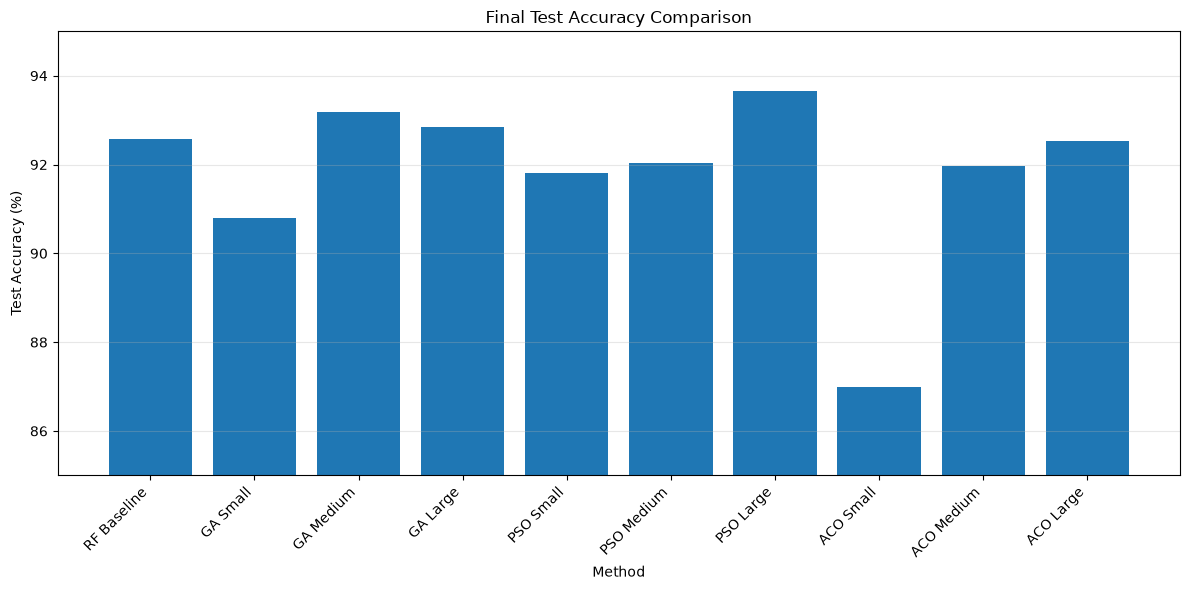

In [19]:
import matplotlib.pyplot as plt

labels = [
    "RF Baseline",
    "GA Small",
    "GA Medium",
    "GA Large",
    "PSO Small",
    "PSO Medium",
    "PSO Large",
    "ACO Small",
    "ACO Medium",
    "ACO Large"
]

accuracy = final_comparison["Test Accuracy (%)"]

plt.figure(figsize=(12, 6))

plt.bar(labels, accuracy)

plt.xlabel("Method")
plt.ylabel("Test Accuracy (%)")
plt.title("Final Test Accuracy Comparison")
plt.xticks(rotation=45, ha="right")

plt.ylim(85, 95)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

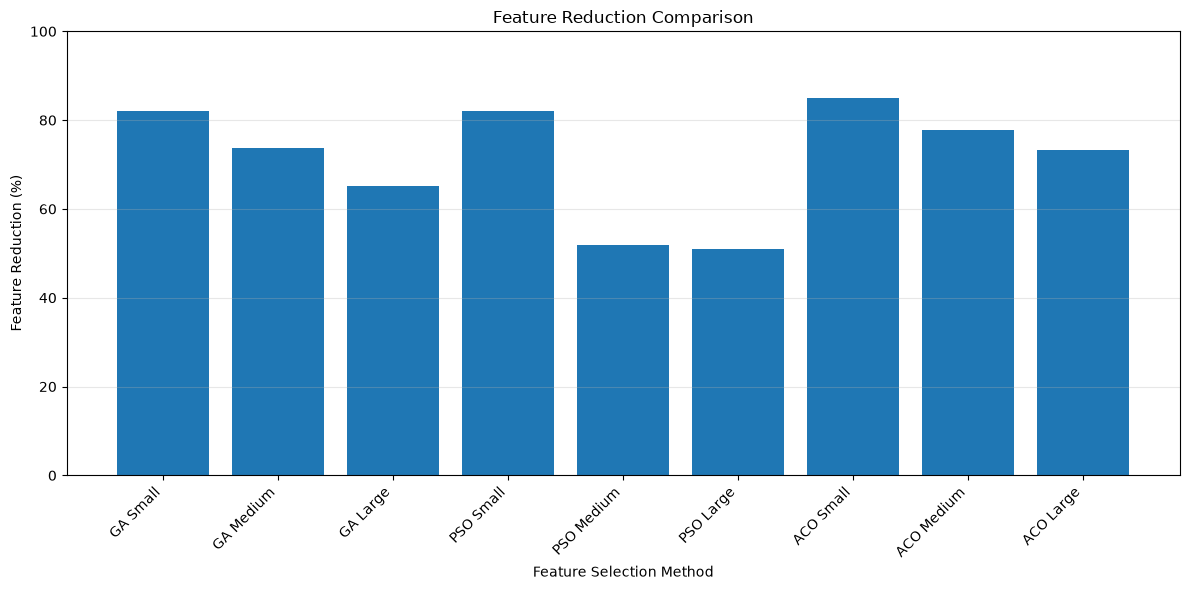

In [20]:
import matplotlib.pyplot as plt

labels = [
    "GA Small",
    "GA Medium",
    "GA Large",
    "PSO Small",
    "PSO Medium",
    "PSO Large",
    "ACO Small",
    "ACO Medium",
    "ACO Large"
]

reduction = final_comparison[
    final_comparison["Algorithm"] != "Random Forest Baseline"
]["Feature Reduction (%)"]

plt.figure(figsize=(12, 6))

plt.bar(labels, reduction)

plt.xlabel("Feature Selection Method")
plt.ylabel("Feature Reduction (%)")
plt.title("Feature Reduction Comparison")

plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

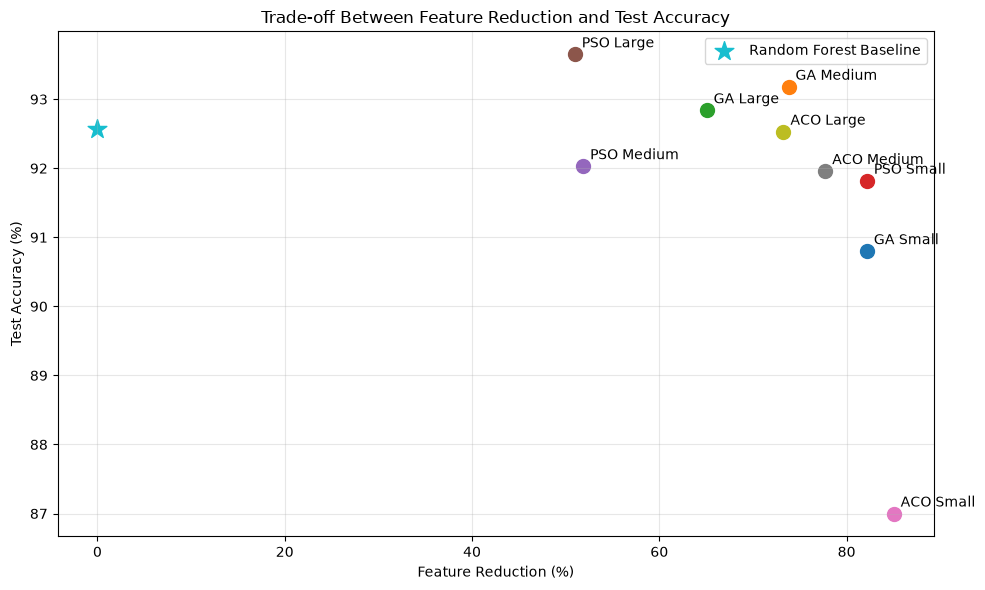

In [21]:
import matplotlib.pyplot as plt

methods = final_comparison[
    final_comparison["Algorithm"] != "Random Forest Baseline"
].copy()

labels = (
    methods["Algorithm"] + " " + methods["Problem Size"]
)

plt.figure(figsize=(10, 6))

for i in range(len(methods)):
    plt.scatter(
        methods.iloc[i]["Feature Reduction (%)"],
        methods.iloc[i]["Test Accuracy (%)"],
        s=100
    )
    
    plt.annotate(
        labels.iloc[i],
        (
            methods.iloc[i]["Feature Reduction (%)"],
            methods.iloc[i]["Test Accuracy (%)"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

baseline = final_comparison[
    final_comparison["Algorithm"] == "Random Forest Baseline"
].iloc[0]

plt.scatter(
    baseline["Feature Reduction (%)"],
    baseline["Test Accuracy (%)"],
    marker="*",
    s=200,
    label="Random Forest Baseline"
)

plt.xlabel("Feature Reduction (%)")
plt.ylabel("Test Accuracy (%)")
plt.title("Trade-off Between Feature Reduction and Test Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
best_results = (
    final_comparison[
        final_comparison["Algorithm"] != "Random Forest Baseline"
    ]
    .sort_values("Test Accuracy (%)", ascending=False)
    .groupby("Algorithm", as_index=False)
    .first()
)

display(
    best_results[
        [
            "Algorithm",
            "Problem Size",
            "Selected Features",
            "Feature Reduction (%)",
            "Test Accuracy (%)",
            "Test Macro-F1 (%)",
            "Training Time (seconds)",
            "Prediction Time (seconds)"
        ]
    ]
)

,Algorithm,Problem Size,Selected Features,Feature Reduction (%),Test Accuracy (%),Test Macro-F1 (%),Training Time (seconds),Prediction Time (seconds)
0,ACO,Large,150,73.26,92.53,92.34,2.43,0.10
1,GA,Medium,147,73.80,93.18,92.87,2.48,0.13
2,PSO,Large,275,50.98,93.65,93.38,3.18,0.10


In [23]:
final_comparison.to_csv(
    "final_comparison_results.csv",
    index=False
)

stability_df.to_csv(
    "stability_results.csv",
    index=False
)

stability_summary.to_csv(
    "stability_summary.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
